# Nozzle shock zoom

For each run: an $x$–$y$ slice around pericentre (top) and the slice along the returning orbit, $s$–$z$ (bottom).

## Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import os

import matplotlib.patheffects as path_effects
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle

from dev.io import load_npz
from dev.plotting import MACH_CMAP, MACH_NORM, colorbar_above, log_limits, mach_classes

REPO = "/home/hey4/rich_tde"
PROCESSED = os.path.join(REPO, "data/processed")
SHOCK_ROOT = os.path.join(PROCESSED, "ShockFinderEdissSelection/analysis/zoom-shocks")
OUTPUT_ROOT = os.path.join(REPO, "reports/shockpaper/figures")
os.makedirs(OUTPUT_ROOT, exist_ok=True)

SNAPSHOTS = {"1e4": 77, "1e5": 161, "ss24": 850}
SMOOTHING_RADIUS_RP = 0.6
XY_WINDOW_RP = (-1.0, 2.0, -1.5, 1.5)

SHOCK_FIELDS = (
    ("density", "Density", r"$\log_{10}(\rho/[\mathrm{g\,cm^{-3}}])$", "twilight", 6),
    ("pressure", "Gas pressure", r"$\log_{10}(P/[\mathrm{dyn\,cm^{-2}}])$", "rainbow", 6),
    ("mach", "Mach number", r"$\mathcal{M}$", MACH_CMAP, None),
    ("dissipation", "Dissipation", r"$\log_{10}(\dot E_{\rm diss}/[\mathrm{erg\,s^{-1}\,cm^{-3}}])$", "viridis", 2),
)
ENERGY_FIELDS = (
    ("vertical_kinetic", "Specific vertical kinetic energy", r"$\log_{10}(\frac{1}{2}|v_z|^2/[\mathrm{erg\,g^{-1}}])$", "magma", 6),
    ("internal_energy", "Specific internal energy", r"$\log_{10}(u/[\mathrm{erg\,g^{-1}}])$", "inferno", 6),
    ("mach", "Mach number", r"$\mathcal{M}$", MACH_CMAP, None),
    ("vertical_mach", "Vertical Mach number", r"$|v_z|/c_s$", MACH_CMAP, None),
)

In [2]:
def load_grids(run):
    snapnum = SNAPSHOTS[run]
    zoom_path = os.path.join(SHOCK_ROOT, f"nozzle-orbit-zoom50/{run}/nozzle_orbit_zoom50_snap_{snapnum:04d}.npz")
    slices = load_npz(os.path.join(PROCESSED, f"NozzleZoomSlices/{run}/grids/nozzle_zoom_snap_{snapnum:04d}_768.npz"))
    zoom_xy = load_npz(zoom_path, prefix="nozzle_xy_")
    xy_mach = load_npz(os.path.join(SHOCK_ROOT, f"mach-slices/{run}/mach_P_snap_{snapnum:04d}.npz"))["nozzle_xy_mach_P"]

    x, y = slices["x_rp"], slices["y_rp"]
    inside_smoothing = np.hypot(x[:, None], y[None, :]) < SMOOTHING_RADIUS_RP
    xy = {
        name: np.where(inside_smoothing, np.nan, grid)
        for name, grid in {
            "density": slices["density"],
            "pressure": slices["pressure"],
            "dissipation": slices["dissipation"],
            "mach": xy_mach,
            "vertical_kinetic": zoom_xy["specific_vertical_kinetic"],
            "internal_energy": zoom_xy["specific_internal_energy"],
            "vertical_mach": zoom_xy["abs_vz_over_cs"],
            "vx": slices["vx_kms"],
            "vy": slices["vy_kms"],
        }.items()
    }
    xy.update(x=x, y=y, time_tfb=slices["time_tfb"])

    orbit = load_npz(zoom_path, prefix="nozzle_orbit_")
    orbit.update(
        s=orbit["s_rsun"],
        z=orbit["z_rsun"],
        mach=orbit["mach_P"],
        vertical_kinetic=orbit["specific_vertical_kinetic"],
        internal_energy=orbit["specific_internal_energy"],
        vertical_mach=orbit["abs_vz_over_cs"],
    )
    return xy, orbit

In [3]:
def draw_field(ax, x, y, values, name, cmap, limits):
    if limits is None:
        classes = mach_classes(values, shocks_only=name == "mach")
        return ax.pcolormesh(x, y, classes.T, cmap=MACH_CMAP, norm=MACH_NORM, shading="auto", rasterized=True)
    cmap = plt.get_cmap(cmap)
    cmap = cmap.with_extremes(bad=cmap(0.0))
    return ax.pcolormesh(x, y, values.T, cmap=cmap, vmin=limits[0], vmax=limits[1], shading="auto", rasterized=True)


def mark_nozzle(ax, orbit):
    ax.set(xlim=XY_WINDOW_RP[:2], ylim=XY_WINDOW_RP[2:], box_aspect=1, xlabel=r"$x/r_p$")
    ax.add_patch(Circle((0, 0), SMOOTHING_RADIUS_RP, facecolor="black", edgecolor="none", zorder=8))
    ax.plot(orbit["x_rp"], orbit["y_rp"], color="red", linewidth=1.5, zorder=12)
    label_angle = np.deg2rad(55)
    for radius, label in ((SMOOTHING_RADIUS_RP, r"$r_0$"), (1.0, r"$r_p$")):
        ax.add_patch(Circle((0, 0), radius, fill=False, edgecolor="white", linestyle="--", linewidth=0.9, zorder=10))
        ax.text(
            radius * np.cos(label_angle) + 0.025,
            radius * np.sin(label_angle) + 0.025,
            label,
            color="white",
            fontsize=9,
            va="bottom",
            path_effects=[path_effects.withStroke(linewidth=1.3, foreground="black")],
            zorder=11,
        )


def orbit_streamlines(ax, orbit):
    s = orbit["s"]
    uniform_s = np.linspace(s[0], s[-1], s.size)

    def resample(field):
        return np.stack([np.interp(uniform_s, s, column) for column in field.T], axis=1)

    ds_dt = orbit["dphi_dt"] * np.gradient(s, orbit["phi"])[:, None]
    ax.streamplot(
        uniform_s, orbit["z"], resample(ds_dt).T, resample(orbit["dz_rsun_dt"]).T,
        color="white", density=0.8, linewidth=0.55, arrowsize=0.75,
    )

In [4]:
def nozzle_figure(run, fields, streamline_column, name):
    xy, orbit = load_grids(run)
    fig, axes = plt.subplots(
        2, 4, figsize=(12, 5.8), gridspec_kw={"height_ratios": (2, 1), "wspace": 0.08, "hspace": 0.22}
    )
    for (top, bottom), (field, title, label, cmap, decades) in zip(axes.T, fields):
        both_rows = np.concatenate((xy[field].ravel(), orbit[field].ravel()))
        limits = None if decades is None else log_limits(both_rows, decades)
        image = draw_field(top, xy["x"], xy["y"], xy[field], field, cmap, limits)
        draw_field(bottom, orbit["s"], orbit["z"], orbit[field], field, cmap, limits)
        colorbar_above(fig, top, image, label)
        top.set_title(title, pad=43)
        mark_nozzle(top, orbit)
        bottom.set(box_aspect=0.5, xlim=orbit["s"][[0, -1]], ylim=orbit["z"][[0, -1]], xlabel=r"$s-s_p\ [R_\odot]$")

    axes[0, streamline_column].streamplot(
        xy["x"], xy["y"], xy["vx"].T, xy["vy"].T, color="white", density=1.0, linewidth=0.5, arrowsize=0.7
    )
    orbit_streamlines(axes[1, streamline_column], orbit)
    axes[0, 0].set_ylabel(r"$y/r_p$", labelpad=2)
    axes[1, 0].set_ylabel(r"$z/R_\odot$", labelpad=2)
    for ax in axes[:, 1:].flat:
        ax.tick_params(labelleft=False)
    for ax in axes.flat:
        ax.tick_params(labelsize=8)
    fig.subplots_adjust(left=0.055, right=0.995, bottom=0.08, top=0.86)

    output = os.path.join(OUTPUT_ROOT, f"{name}_{run}_snap_{SNAPSHOTS[run]:04d}.png")
    fig.savefig(output, dpi=240, facecolor="white")
    print(
        f"{run} | snap {SNAPSHOTS[run]} | t/t_fb={xy['time_tfb']:.4f} | "
        f"orbit box scale={orbit['box_scale']:g}, radius scale={orbit['radius_scale']:g}, "
        f"phase offset={orbit['phase_deg']:+g} deg, s shift={orbit['center_shift_rsun']:+g} R_sun | "
        f"shocked pixels: xy={np.count_nonzero(np.nan_to_num(xy['mach'])):,}, "
        f"orbit={np.count_nonzero(orbit['mach']):,} | {output}"
    )
    plt.show()

## Shocks and dissipation

1e4 | snap 77 | t/t_fb=0.9990 | orbit box scale=0.5, radius scale=0.9, phase offset=+0 deg, s shift=-4 R_sun | shocked pixels: xy=9,882, orbit=40,772 | /home/hey4/rich_tde/reports/shockpaper/figures/nozzle_shocks_1e4_snap_0077.png


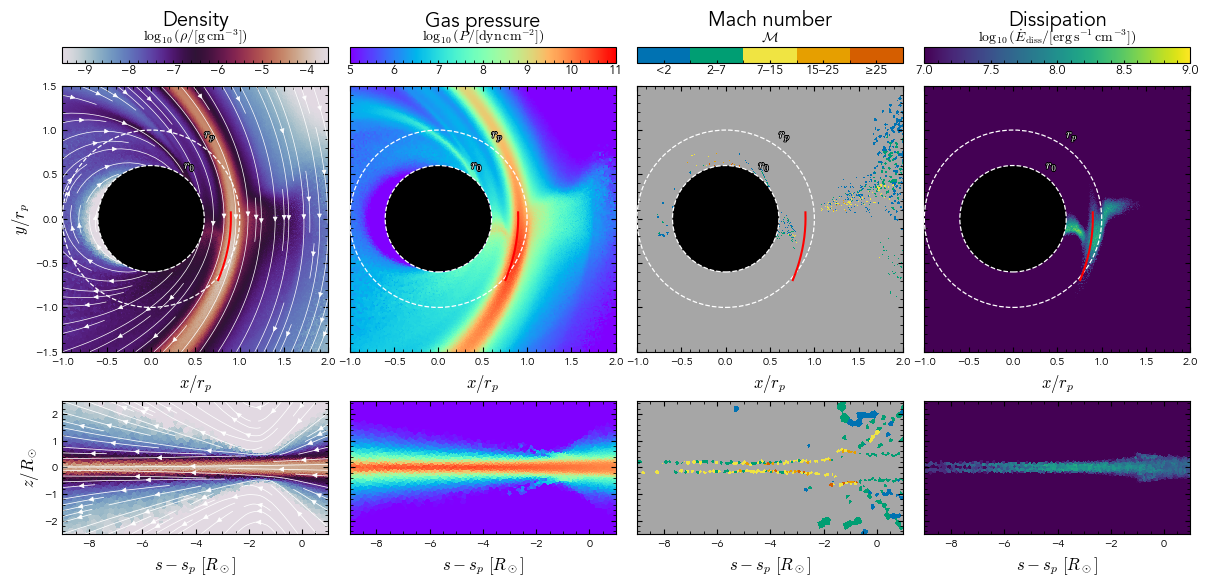

1e5 | snap 161 | t/t_fb=0.6058 | orbit box scale=0.6, radius scale=1, phase offset=-13 deg, s shift=-3 R_sun | shocked pixels: xy=62,761, orbit=116,919 | /home/hey4/rich_tde/reports/shockpaper/figures/nozzle_shocks_1e5_snap_0161.png


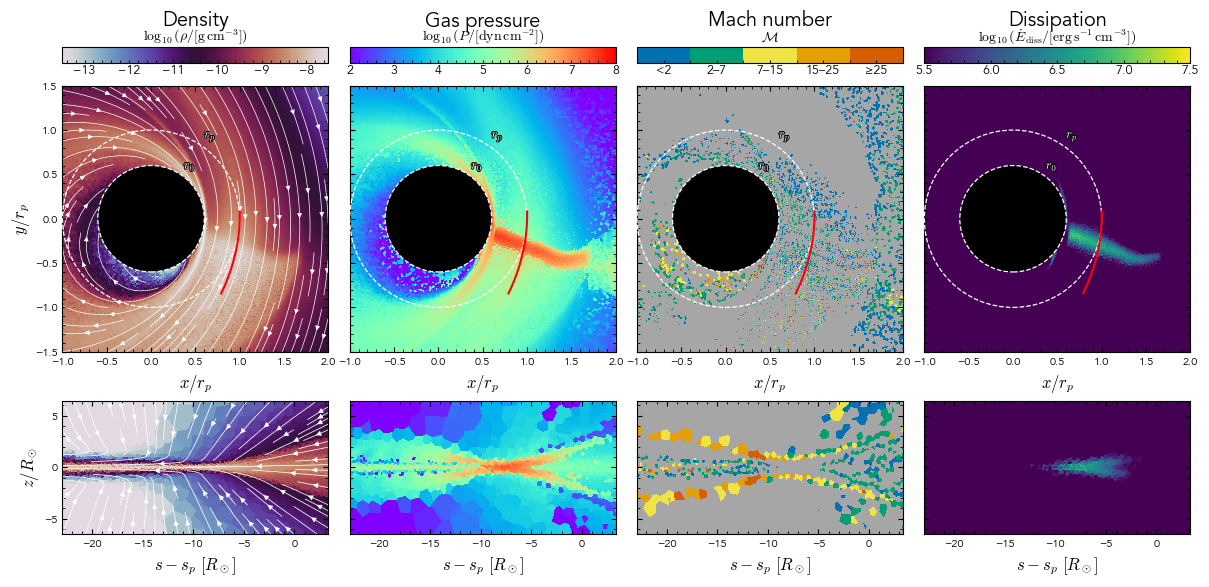

ss24 | snap 850 | t/t_fb=1.0015 | orbit box scale=0.6, radius scale=1, phase offset=-13 deg, s shift=-40 R_sun | shocked pixels: xy=45,474, orbit=48,271 | /home/hey4/rich_tde/reports/shockpaper/figures/nozzle_shocks_ss24_snap_0850.png


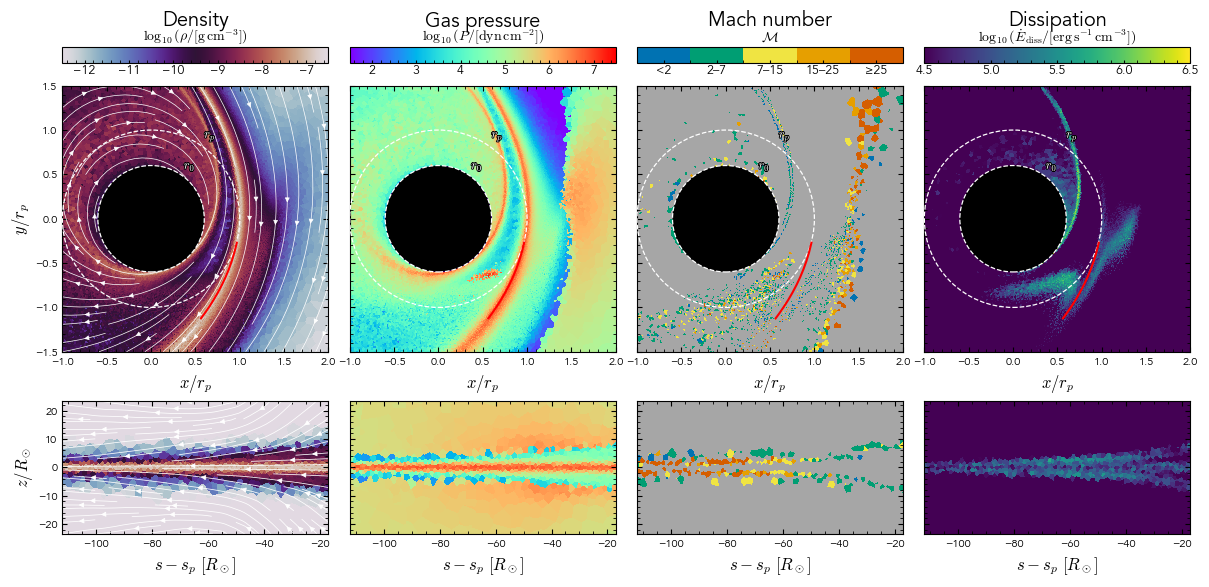

In [5]:
for run in SNAPSHOTS:
    nozzle_figure(run, SHOCK_FIELDS, streamline_column=0, name="nozzle_shocks")

## Energies and Mach numbers

1e4 | snap 77 | t/t_fb=0.9990 | orbit box scale=0.5, radius scale=0.9, phase offset=+0 deg, s shift=-4 R_sun | shocked pixels: xy=9,882, orbit=40,772 | /home/hey4/rich_tde/reports/shockpaper/figures/nozzle_energies_mach_1e4_snap_0077.png


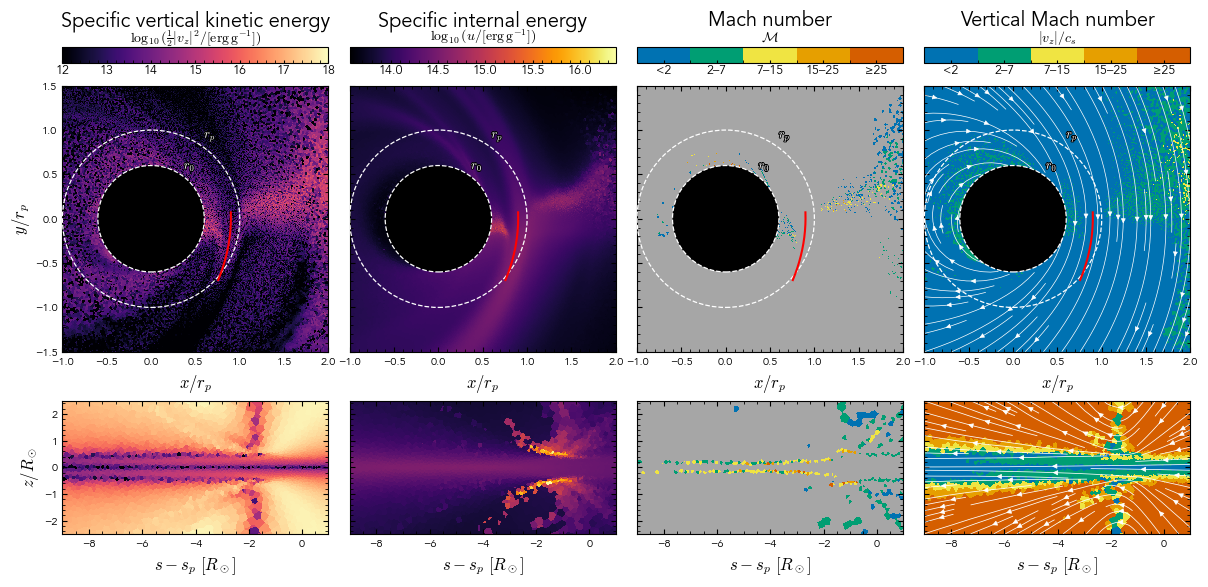

1e5 | snap 161 | t/t_fb=0.6058 | orbit box scale=0.6, radius scale=1, phase offset=-13 deg, s shift=-3 R_sun | shocked pixels: xy=62,761, orbit=116,919 | /home/hey4/rich_tde/reports/shockpaper/figures/nozzle_energies_mach_1e5_snap_0161.png


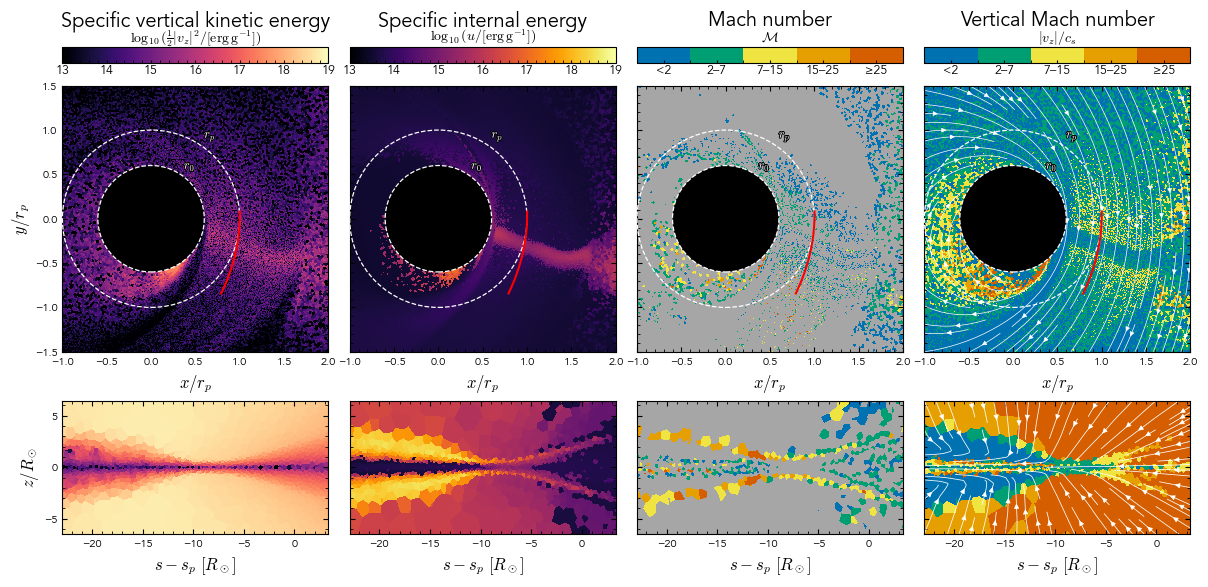

ss24 | snap 850 | t/t_fb=1.0015 | orbit box scale=0.6, radius scale=1, phase offset=-13 deg, s shift=-40 R_sun | shocked pixels: xy=45,474, orbit=48,271 | /home/hey4/rich_tde/reports/shockpaper/figures/nozzle_energies_mach_ss24_snap_0850.png


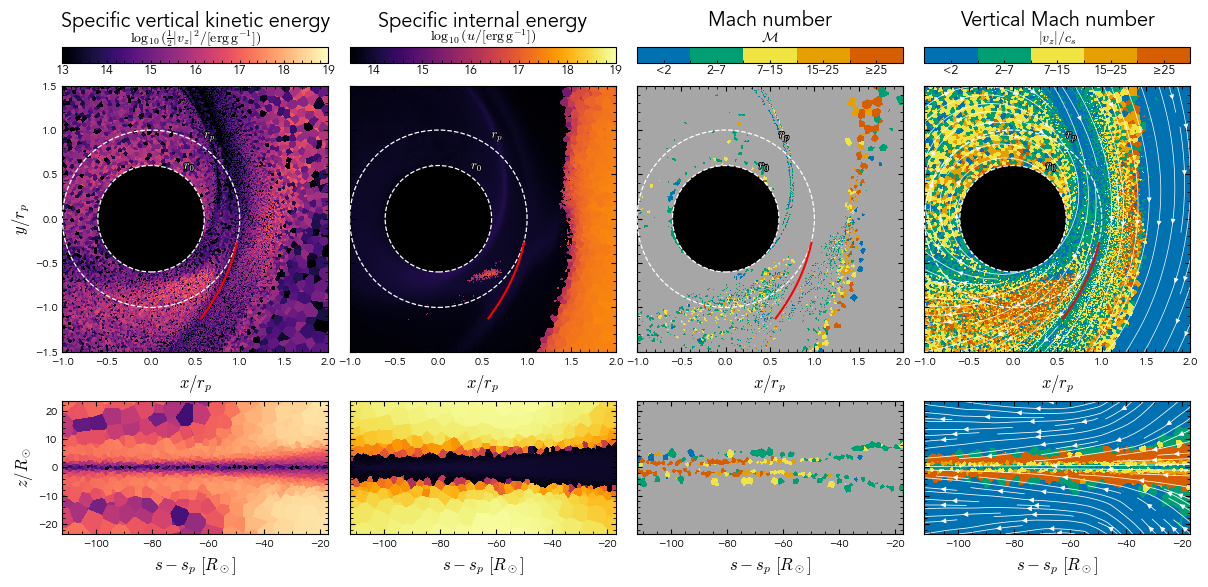

In [6]:
for run in SNAPSHOTS:
    nozzle_figure(run, ENERGY_FIELDS, streamline_column=3, name="nozzle_energies_mach")